# Models #
- ARIMA
- SARIMA
- SARIMAX


In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import ARIMA, auto_arima
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.deterministic import Fourier
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.preprocessing import StandardScaler

import GPy

from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

from typing import Tuple

In [2]:
parquet_directory = '../../data'
metadata_file = f'{parquet_directory}/metadata.parquet'
demand_file = f'{parquet_directory}/demand.parquet'
weather_file = f'{parquet_directory}/weather.parquet'

metadata = pd.read_parquet(metadata_file)
demand = pd.read_parquet(demand_file)
weather = pd.read_parquet(weather_file)

In [3]:
# Xóa các cột không có dữ liệu
weather.drop(columns=['snowfall', 'snow_depth'], inplace=True)
weather.head()

,timestamp,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,weather_code,pressure_msl,surface_pressure,...,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm,is_day,sunshine_duration,shortwave_radiation,direct_radiation,diffuse_radiation,direct_normal_irradiance,terrestrial_radiation,location_id
0,2021-01-01 00:00:00,10.942499,91.550140,9.5925,9.636084,0.0,0.0,1.0,1018.599976,1012.104858,...,0.401,0.4110,0.0,0.0,0.0,0.0,0.0,0.0,0.0,sp1jpqedrbm7
1,2021-01-01 01:00:00,10.717500,91.521149,9.3675,9.368031,0.0,0.0,0.5,1019.000000,1012.498291,...,0.401,0.4105,0.0,0.0,0.0,0.0,0.0,0.0,0.0,sp1jpqedrbm7
2,2021-01-01 02:00:00,10.592500,92.114464,9.3425,9.177265,0.0,0.0,1.5,1019.000000,1012.496277,...,0.401,0.4100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,sp1jpqedrbm7
3,2021-01-01 03:00:00,10.542500,91.966637,9.2675,9.107465,0.0,0.0,1.0,1019.150024,1012.644775,...,0.401,0.4100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,sp1jpqedrbm7
4,2021-01-01 04:00:00,10.342500,92.286560,9.1175,8.865026,0.0,0.0,1.0,1019.349976,1012.840088,...,0.400,0.4095,0.0,0.0,0.0,0.0,0.0,0.0,0.0,sp1jpqedrbm7


**Metadata**
- Time period
- Daily Meter Count

In [4]:
london_data_ids = metadata[metadata['dataset'] == "Electricity Load Diagrams"]['unique_id'].unique()
london_demand = demand[demand['unique_id'].isin(london_data_ids)]

start_date = london_demand['timestamp'].min()
end_date = london_demand['timestamp'].max()
total_days = (end_date - start_date).days
total_years = total_days / 365

print("Electricity Load Diagrams:")
print(f"  Start Date: {start_date}")
print(f"  End Date: {end_date}")
print(f"  Total Years: {total_years:.2f}")


Electricity Load Diagrams:
  Start Date: 2021-01-01 00:30:00
  End Date: 2025-01-01 00:00:00
  Total Years: 4.00


In [5]:
combined_df = pd.merge(demand, metadata, on='unique_id', how='inner')

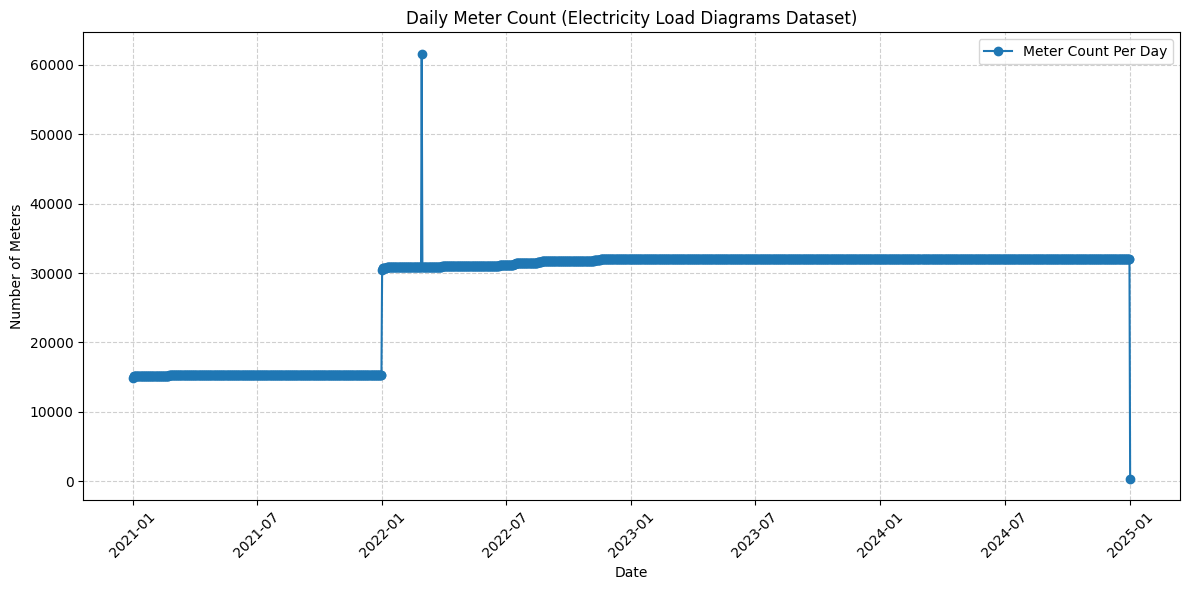

In [6]:
london_combined_df = combined_df[combined_df['dataset'] == 'Electricity Load Diagrams']

london_combined_df['date'] = london_combined_df['timestamp'].dt.date

daily_meter_count = london_combined_df.groupby('date')['building_id'].count().reset_index()
daily_meter_count.rename(columns={'building_id': 'meter_count'}, inplace=True)

truncated_daily_meter_count = daily_meter_count[daily_meter_count['date'] <= pd.to_datetime('2025-01-01').date()]

plt.figure(figsize=(12, 6))
plt.plot(truncated_daily_meter_count['date'], truncated_daily_meter_count['meter_count'], marker='o', label='Meter Count Per Day')
plt.title("Daily Meter Count (Electricity Load Diagrams Dataset)")
plt.xlabel("Date")
plt.ylabel("Number of Meters")
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Để giải quyết vấn đề số lượng đồng hồ đo tăng dần theo thời gian, nhóm quyết định mô hình hóa mức tiêu thụ trung bình theo từng đồng hồ đo thay vì tổng mức tiêu thụ. Cách tiếp cận này chuẩn hóa dữ liệu bằng cách tính đến sự thay đổi về số lượng đồng hồ đo, đảm bảo rằng phân tích tập trung vào xu hướng tiêu thụ trên từng đồng hồ đo thay vì bị sai lệch bởi sự biến động của tổng số đồng hồ đo.

**Tiền xử lý dữ liệu:**
- Lọc các mốc thời gian hợp lệ theo chu kỳ 15 phút
- Tổng hợp dữ liệu đồng hồ đo theo ngày
- Tính trung bình mức tiêu thụ theo từng đồng hồ đo
- Chia tập huấn luyện/kiểm tra theo: train (1-1-2021 --> 1-1-2024), test (1-1-2024 --> 1-1-2025)

In [7]:
pd.to_datetime("2024-01-01").date()

datetime.date(2024, 1, 1)

In [8]:
london_demand['timestamp'] = pd.to_datetime(london_demand['timestamp'], errors='coerce')
valid_offsets_set = set(pd.date_range("00:00", "23:59", freq="15T").strftime("%H:%M"))
london_demand['time_offset'] = london_demand['timestamp'].dt.strftime("%H:%M")
london_demand = london_demand[london_demand['time_offset'].isin(valid_offsets_set)]
london_demand = london_demand.drop(columns=['time_offset'])

london_demand['date'] = london_demand['timestamp'].dt.date  

daily_demand = london_demand.groupby('date')['y'].mean().reset_index() 

 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\3055875491.py:2: FutureWarning:'T' is deprecated and will be removed in a future version, please use 'min' instead.


**Split data**

In [9]:
# Chia dữ liệu theo ngày đầu tiên của năm 2024
split_date_daily = "2024-01-01"
split_date_daily = pd.to_datetime(split_date_daily).date()  

train_data_daily = daily_demand[daily_demand['date'] < split_date_daily]
test_data_daily = daily_demand[daily_demand['date'] >= split_date_daily]

In [10]:
daily_demand.head()

,date,y
0,2021-01-01,114.201174
1,2021-01-02,183.632417
2,2021-01-03,185.407964
3,2021-01-04,189.014090
4,2021-01-05,189.902214


**Trực quan hóa dữ liệu để hiểu:**
- Tính chu kỳ
- Bậc của quá trình AR và MA
- Tính dừng

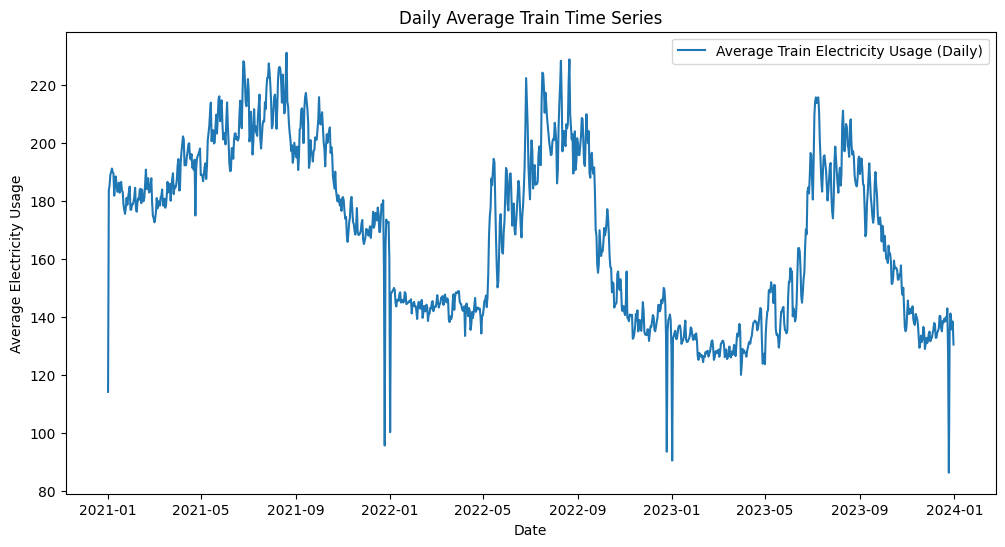

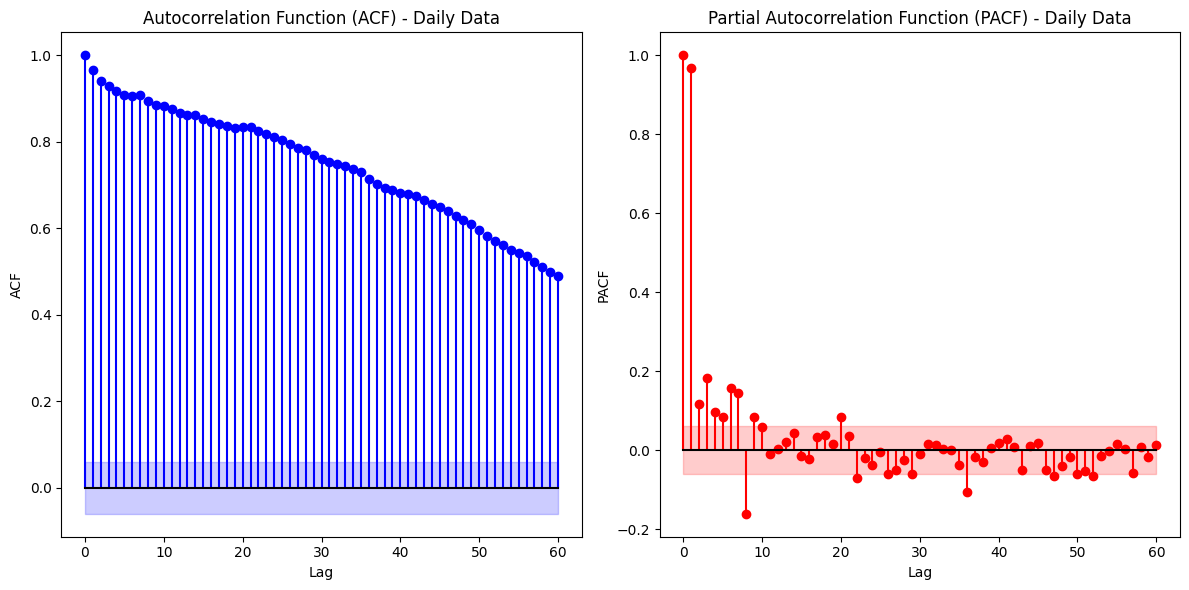

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(train_data_daily['date'], train_data_daily['y'], label='Average Train Electricity Usage (Daily)')
plt.title("Daily Average Train Time Series")
plt.xlabel("Date")
plt.ylabel("Average Electricity Usage")
plt.legend()
plt.show()

train_signal_daily = train_data_daily['y'].to_numpy()

n_lags_daily = 60 
acf_estimate_daily = acf(train_signal_daily, nlags=n_lags_daily)
pacf_estimate_daily = pacf(train_signal_daily, nlags=n_lags_daily)
acf_error_estimate_daily = 2 / np.sqrt(len(train_signal_daily))
pacf_error_estimate_daily = 2 / np.sqrt(len(train_signal_daily))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.stem(range(len(acf_estimate_daily)), acf_estimate_daily, linefmt='b', basefmt='k')
ax1.fill_between(range(len(acf_estimate_daily)), acf_error_estimate_daily, -acf_error_estimate_daily, color='blue', alpha=0.2)
ax1.set_title("Autocorrelation Function (ACF) - Daily Data")
ax1.set_xlabel("Lag")
ax1.set_ylabel("ACF")

ax2.stem(range(len(pacf_estimate_daily)), pacf_estimate_daily, linefmt='r', basefmt='k')
ax2.fill_between(range(len(pacf_estimate_daily)), pacf_error_estimate_daily, -pacf_error_estimate_daily, color='red', alpha=0.2)
ax2.set_title("Partial Autocorrelation Function (PACF) - Daily Data")
ax2.set_xlabel("Lag")
ax2.set_ylabel("PACF")

plt.tight_layout()
plt.show()

Chuỗi thời gian dữ liệu thô thể hiện tính chu kỳ hàng năm. ACF cho thấy tính chu kỳ 7 ngày mà không có quá trình MA rõ ràng, trong khi PACF gợi ý một quá trình AR bậc một. Dưới đây, nhóm mở rộng ACF và PACF thêm để xem liệu có thể phát hiện tính chu kỳ hàng năm hay không.

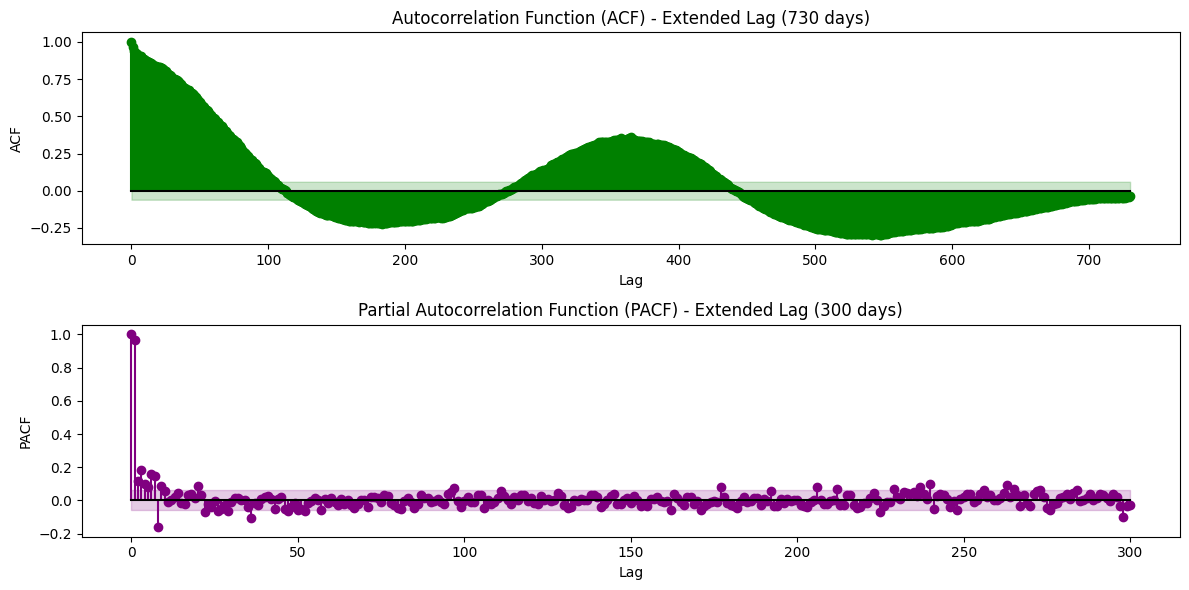

In [12]:
extended_n_lags = int(365 * 2)
extended_n_lags_2 = 300
extended_acf_estimate_daily = acf(train_signal_daily, nlags=extended_n_lags)
extended_acf_error_estimate_daily = 2 / np.sqrt(len(train_signal_daily))

extended_pacf_estimate_daily = pacf(train_signal_daily, nlags=extended_n_lags_2)
extended_pacf_error_estimate_daily = 2 / np.sqrt(len(train_signal_daily))

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].stem(range(len(extended_acf_estimate_daily)), extended_acf_estimate_daily, linefmt='g', basefmt='k')
axes[0].fill_between(range(len(extended_acf_estimate_daily)), extended_acf_error_estimate_daily, -extended_acf_error_estimate_daily, color='green', alpha=0.2)
axes[0].set_title(f"Autocorrelation Function (ACF) - Extended Lag ({extended_n_lags} days)")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("ACF")

axes[1].stem(range(len(extended_pacf_estimate_daily)), extended_pacf_estimate_daily, linefmt='purple', basefmt='k')
axes[1].fill_between(range(len(extended_pacf_estimate_daily)), extended_pacf_error_estimate_daily, -extended_pacf_error_estimate_daily, color='purple', alpha=0.2)
axes[1].set_title(f"Partial Autocorrelation Function (PACF) - Extended Lag ({extended_n_lags_2} days)")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

Các lag mở rộng của ACF cho thấy tính chu kỳ hàng năm trong dữ liệu. Nhóm cũng thực hiện Fourier Transform trên dữ liệu thô để kiểm tra tính chu kỳ.

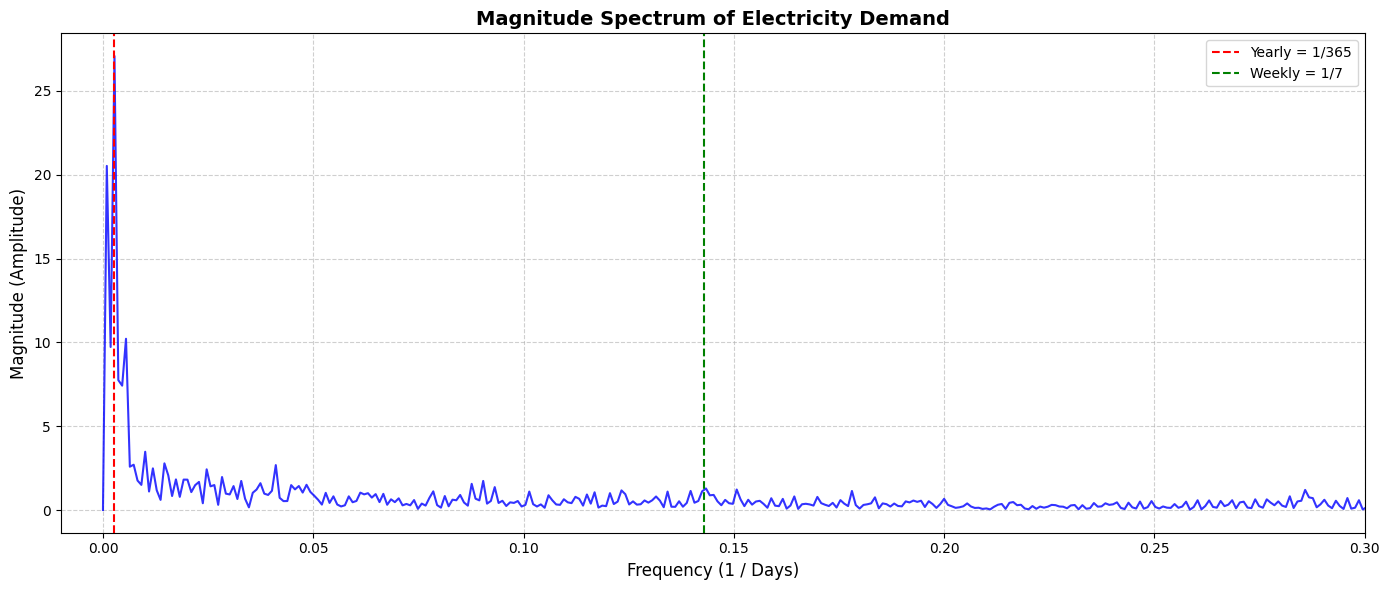

In [13]:
def plot_fourier_magnitude(dt: float, signal: np.ndarray, title: str):
    # 1. Trừ đi giá trị trung bình để loại bỏ mốc Tần số vô hướng = 0 (DC component)
    signal_centered = signal - np.mean(signal)
    
    # 2. Sinh tập tần số và thực hiện FFT
    frequencies = np.fft.rfftfreq(len(signal_centered), d=dt)
    fft_values = np.fft.rfft(signal_centered)
    
    # 3. Tính Biên độ tuyệt đối (Magnitude) 
    # Mẹo: Nhân 2 và chia cho len(signal) để scale biên độ về đúng đơn vị của dữ liệu gốc
    magnitude = 2 * np.abs(fft_values) / len(signal_centered)


    
    plt.figure(figsize=(14, 6))
    
    # Dùng Line plot thay vì Scatter plot để dễ dàng quan sát các đỉnh (peaks)
    plt.plot(frequencies, magnitude, color='blue', alpha=0.8, linewidth=1.5)
    
    yearly_freq = 1/365
    weekly_freq = 1/7
    plt.axvline(yearly_freq, color='red', linestyle='--', label=f'Yearly = 1/365')
    plt.axvline(weekly_freq, color='green', linestyle='--', label=f'Weekly = 1/7')
    
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('Frequency (1 / Days)', fontsize=12)
    plt.ylabel('Magnitude (Amplitude)', fontsize=12)
    
    # 4. Giới hạn trục X lại vùng tần số thấp (0 --> 0.3)
    # Vì tần số > 0.3 thường là nhiễu rác (noise) không mang nhiều ý nghĩa chu kỳ ngày
    plt.xlim(-0.01, 0.3)
    
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
dt=1
plot_fourier_magnitude(dt, train_signal_daily, "Magnitude Spectrum of Electricity Demand")

Fourier Transform càng củng cố thêm rằng dữ liệu này có hai tính chu kỳ -- hàng tuần và hàng năm.

Tiếp theo, kiểm tra tính dừng. Vì vậy, nhóm đã thực hiện Kiểm định Augmented Dickey-Fuller (ADF).

Nếu p-value thấp hơn ngưỡng (0,05), chuỗi được coi là có tính dừng.

In [14]:
adf_test = adfuller(train_signal_daily)
print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}")  

ADF Statistic: -1.3560381241038926
p-value: 0.6031612723250014


Do p-value cao hơn ngưỡng, tiến hành sai phân dữ liệu một lần.

In [15]:
differenced_series = daily_demand.diff().dropna() 

differenced_train_signal = differenced_series['y'].to_numpy()
adf_test = adfuller(differenced_train_signal)
print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}") 

ADF Statistic: -10.041395561505635
p-value: 1.4930070346438404e-17


Và bây giờ p-value đã thấp hơn ngưỡng và dữ liệu được coi là có tính dừng. Điều này cũng có thể thấy rõ trong biểu đồ bên dưới của dữ liệu thô sau khi sai phân một lần.

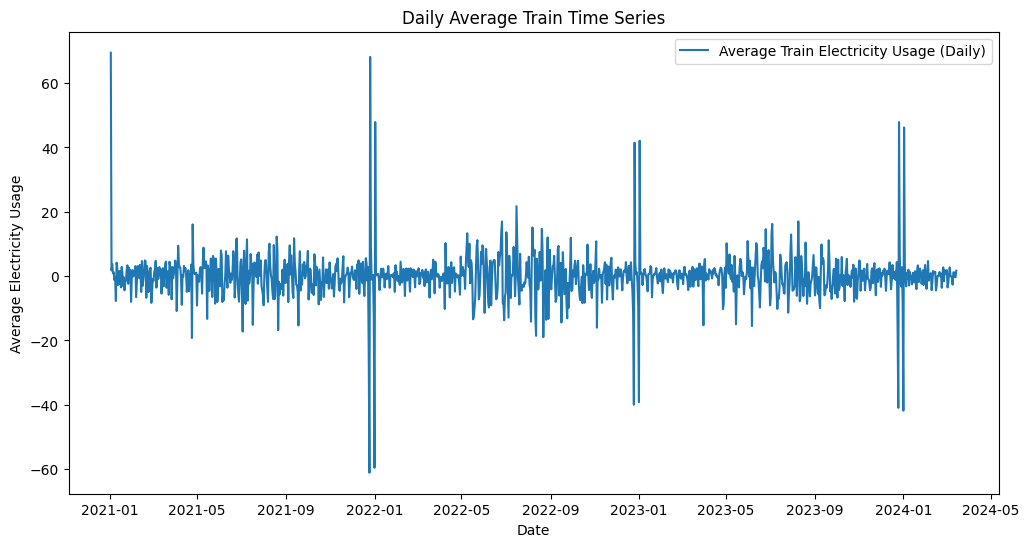

In [16]:
differenced_series = daily_demand[['date']].copy()
differenced_series['y'] = daily_demand['y'].diff()
differenced_series = differenced_series.dropna().reset_index(drop=True)

differenced_series['date'] = pd.to_datetime(differenced_series['date'])

split_date_daily = differenced_series['date'].min() + pd.Timedelta(days=0.8 * (differenced_series['date'].max() - differenced_series['date'].min()).days)
train_data_daily_differenced = differenced_series[differenced_series['date'] < split_date_daily]
test_data_daily_differenced = differenced_series[differenced_series['date'] >= split_date_daily]

plt.figure(figsize=(12, 6))
plt.plot(train_data_daily_differenced['date'], train_data_daily_differenced['y'], label='Average Train Electricity Usage (Daily)')
plt.title("Daily Average Train Time Series")
plt.xlabel("Date")
plt.ylabel("Average Electricity Usage")
plt.legend()
plt.show()

**Modeling**

Nhóm bắt đầu bằng cách thử mô hình hóa ARMA(1,0,0) dựa trên kiểm tra trực quan PACF và ACF của dữ liệu thô, tương tự như những gì đã học

Fitting the ARIMA(1, 0, 0) model on the entire training dataset...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.


Forecasting...
Evaluation Metrics:
  MAPE: 0.1577
  RMSE: 25.1726
  Log-Likelihood: -3711.9137
  AIC: 7429.8275


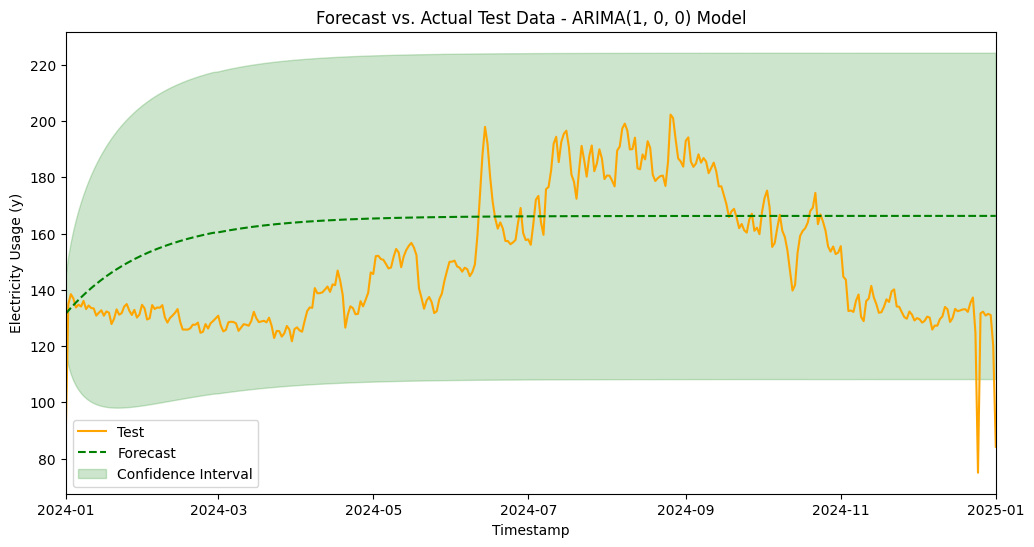

In [17]:
from statsmodels.tsa.arima.model import ARIMA

train_series = train_data_daily.set_index('date')['y']
test_series = test_data_daily.set_index('date')['y']

print("Fitting the ARIMA(1, 0, 0) model on the entire training dataset...")
model = ARIMA(train_series, order=(1, 0, 0))
fitted_model = model.fit()

print("Forecasting...")
forecast_values = fitted_model.forecast(steps=len(test_series))
conf_int = fitted_model.get_forecast(steps=len(test_series)).conf_int()

forecast_values.index = test_series.index
conf_int.index = test_series.index

mape = mean_absolute_percentage_error(test_series, forecast_values)
rmse = np.sqrt(mean_squared_error(test_series, forecast_values))
log_likelihood = fitted_model.llf
aic = fitted_model.aic

print(f"Evaluation Metrics:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_series.index, test_series, label='Test', color='orange')
plt.plot(forecast_values.index, forecast_values, label='Forecast', linestyle='--', color='green')
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='green', alpha=0.2, label='Confidence Interval')
plt.title("Forecast vs. Actual Test Data - ARIMA(1, 0, 0) Model")
plt.xlabel("Timestamp")
plt.ylabel("Electricity Usage (y)")
plt.xlim(test_series.index.min(), test_series.index.max())
plt.legend()
plt.show()


Sau đó, nhóm so sánh ACF lý thuyết của ARIMA(1,0,0) với ACF ước tính được tính từ dữ liệu để xem liệu mô hình ARMA(1,0,0) có nắm bắt phù hợp cấu trúc tự tương quan của dữ liệu hay không, giúp nhóm xác nhận liệu đây có phải là một mô hình phù hợp hay cần điều chỉnh các tham số mô hình

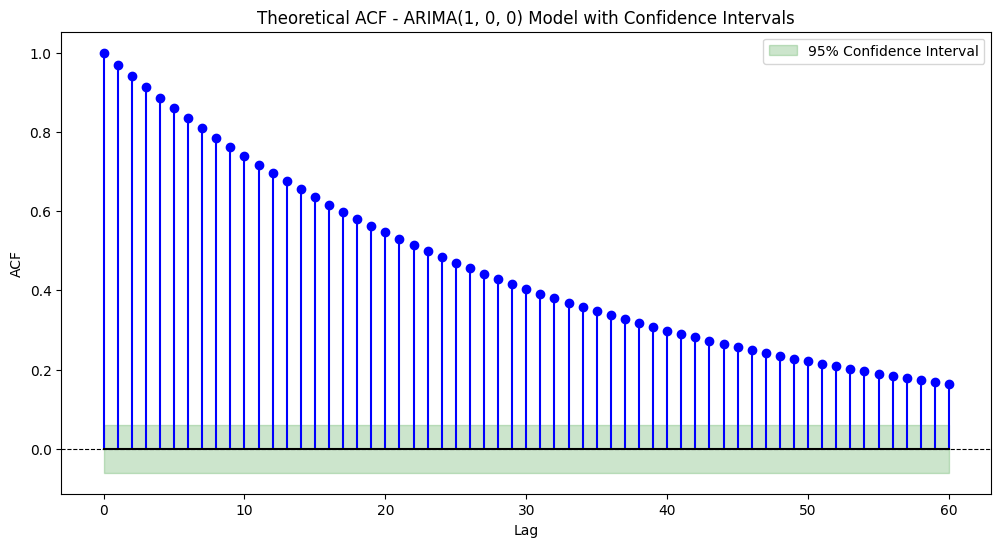

In [18]:
ar_params = fitted_model.arparams 
ma_params = fitted_model.maparams

arma_process = ArmaProcess(np.r_[1, -ar_params], np.r_[1, ma_params])

n_lags = 60
theoretical_acf = arma_process.acf(lags=n_lags + 1)

n_samples = len(train_series)  
conf_interval = 2 / np.sqrt(n_samples)  

plt.figure(figsize=(12, 6))
plt.stem(range(n_lags + 1), theoretical_acf, linefmt='b-', basefmt='k', markerfmt='bo')
plt.axhline(y=0, color='k', linestyle='--', linewidth=0.8)
plt.fill_between(
    range(n_lags + 1), 
    -conf_interval, 
    conf_interval, 
    color='green', alpha=0.2, label="95% Confidence Interval"
)
plt.title("Theoretical ACF - ARIMA(1, 0, 0) Model with Confidence Intervals")
plt.xlabel("Lag")
plt.ylabel("ACF")
plt.legend()
plt.show()

Có vẻ như hàm tự tương quan lý thuyết (ACF) của ARIMA(1,0,0) tương tự với hàm tự tương quan ước tính, tức là mô hình phù hợp tốt. Ngoài ra, chỉ số đánh giá dự báo trên dữ liệu chưa được thấy là khoảng 16% (15,77%). Do đó, ARIMA(1,0,0) là một khởi đầu tốt để mô hình hóa nhu cầu điện trung bình hàng ngày của London.

Nhóm cũng đã thực hiện automated grid search bằng AutoARIMA để xác định các tham số ARIMA tối ưu và so sánh kết quả với các tham số ARIMA được chọn thủ công dựa trên quan sát trực quan.


Fitting ARIMA model using auto_arima...
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=7433.959, Time=0.06 sec


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pmdarima\arima\_validation.py:76: UserWarning:stepwise model cannot be fit in parallel (n_jobs=1). Falling back to stepwise parameter search.


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=7430.535, Time=0.18 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=7426.538, Time=0.21 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=7431.964, Time=0.05 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=7363.725, Time=0.34 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=7352.120, Time=0.52 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=7389.053, Time=0.52 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=7353.038, Time=0.76 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=7337.237, Time=1.19 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=7350.631, Time=0.54 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=7336.486, Time=0.96 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=7312.476, Time=0.65 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=7336.773, Time=0.40 sec
 ARIMA(3,1,4)(0,0,0)[0] intercept   : AIC=7284.236, Time=2.28 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=7290.933, Time=2.37 sec
 ARIMA(3,1,5)(0,0,0)[0] intercept   : AIC=7297.874, Time=3.83 sec
 ARIMA(2,1

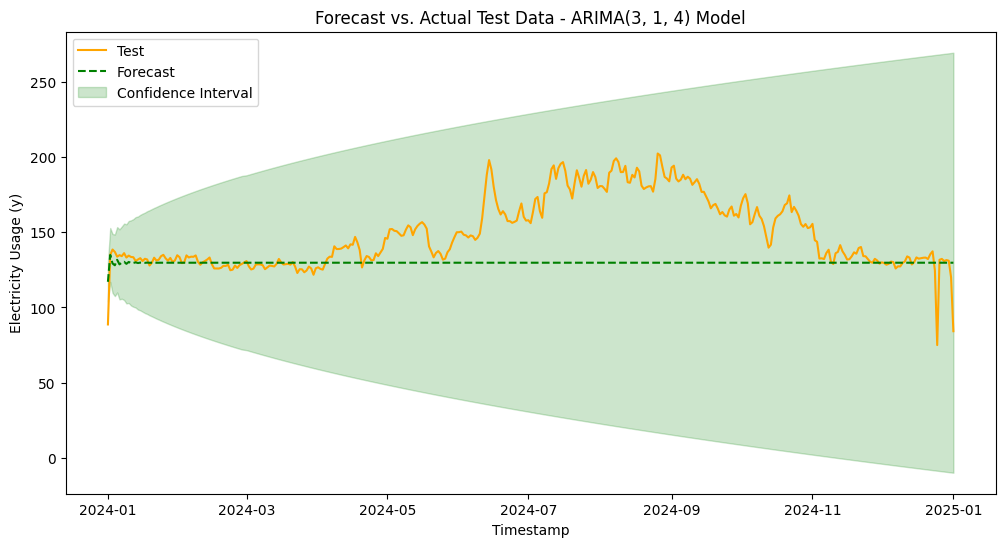

In [19]:
print("Fitting ARIMA model using auto_arima...")
arma_model = auto_arima(
    train_series,
    start_p=0, max_p=3,  
    start_q=0, max_q=5,
    seasonal=False,      
    stepwise=True,       
    trace=True,          
    suppress_warnings=True, 
    information_criterion='aic',  
    n_jobs=-1          
)

print(f"Best ARIMA model order: {arma_model.order}")

print("Forecasting...")
forecast_values, conf_int = arma_model.predict(n_periods=len(test_series), return_conf_int=True)

mape = mean_absolute_percentage_error(test_series, forecast_values)
rmse = np.sqrt(mean_squared_error(test_series, forecast_values))
aic = arma_model.aic()

print(f"Evaluation Metrics:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_series.index, test_series, label='Test', color='orange')
plt.plot(test_series.index, forecast_values, label='Forecast', linestyle='--', color='green')
plt.fill_between(test_series.index, conf_int[:, 0], conf_int[:, 1], color='green', alpha=0.2, label='Confidence Interval')
plt.title(f"Forecast vs. Actual Test Data - ARIMA{arma_model.order} Model")
plt.xlabel("Timestamp")
plt.ylabel("Electricity Usage (y)")
plt.legend()
plt.show()

- Các tham số được lựa chọn bởi automated grid search có sự khác biệt nhẹ, cụ thể là mô hình ARIMA(3,1,4). Sự khác biệt này xuất phát từ việc automated grid search có khả năng đồng thời xem xét phép sai phân (differencing) cùng với các bậc AR và MA, và tối ưu hóa chúng một cách tổng thể. Trong khi đó, phương pháp lựa chọn trực quan gặp khó khăn khi xét d=1, do việc sai phân làm thay đổi thang đo của dữ liệu, khiến việc diễn giải ACF và PACF của chuỗi sau sai phân trở nên kém trực quan hơn

- Để minh họa, nhóm vẫn trình bày biểu đồ ACF và PACF của chuỗi sau khi sai phân bậc 1 như một tài liệu tham khảo. Đồng thời, nhóm cũng so sánh ACF lý thuyết của ARIMA(3,1,4) với ACF ước tính từ dữ liệu đã sai phân và nhận thấy mức độ phù hợp chưa cao. Điều này cho thấy ACF lý thuyết của mô hình này chưa mô tả tốt cấu trúc tự tương quan của dữ liệu sau khi sai phân

- Ngoài ra, cần lưu ý rằng automated grid search tối ưu theo tiêu chí Akaike Information Criterion (AIC), vốn cân bằng giữa độ phù hợp của mô hình (log-likelihood) và độ phức tạp của mô hình (số lượng tham số) trên tập huấn luyện. Do đó, phương pháp này ưu tiên tối ưu độ phù hợp trên tập train hơn là hiệu quả dự báo trên dữ liệu chưa thấy.
Ngược lại, nhóm tập trung đánh giá hiệu suất dự báo trên tập kiểm tra thông qua các chỉ số như MAPE và RMSE, với mục tiêu chính là đánh giá độ chính xác dự báo. Vì vậy, mô hình do automated grid search lựa chọn ARIMA(3,1,4) có MAPE và RMSE cao hơn so với mô hình ARMA(1,0,0) được chọn thủ công, mặc dù có AIC thấp hơn trên tập huấn luyện

- Một điểm đáng chú ý là automated grid search đã xác định được nhu cầu sai phân bậc 1 để đạt tính dừng, phù hợp với kết quả kiểm định ADF trước đó. Điều này cho thấy phương pháp này đặc biệt hữu ích khi mô hình yêu cầu lựa chọn nhiều tham số, chẳng hạn như khi có sai phân hoặc các thành phần mùa vụ

- Cuối cùng, nhóm nhận thấy rằng dự báo từ mô hình hiện tại có xu hướng phẳng và chưa nắm bắt được yếu tố mùa vụ. Do đó, nhóm sẽ tiếp tục cải thiện mô hình bằng cách sử dụng SARIMA để khai thác các thành phần mùa vụ trong dữ liệu

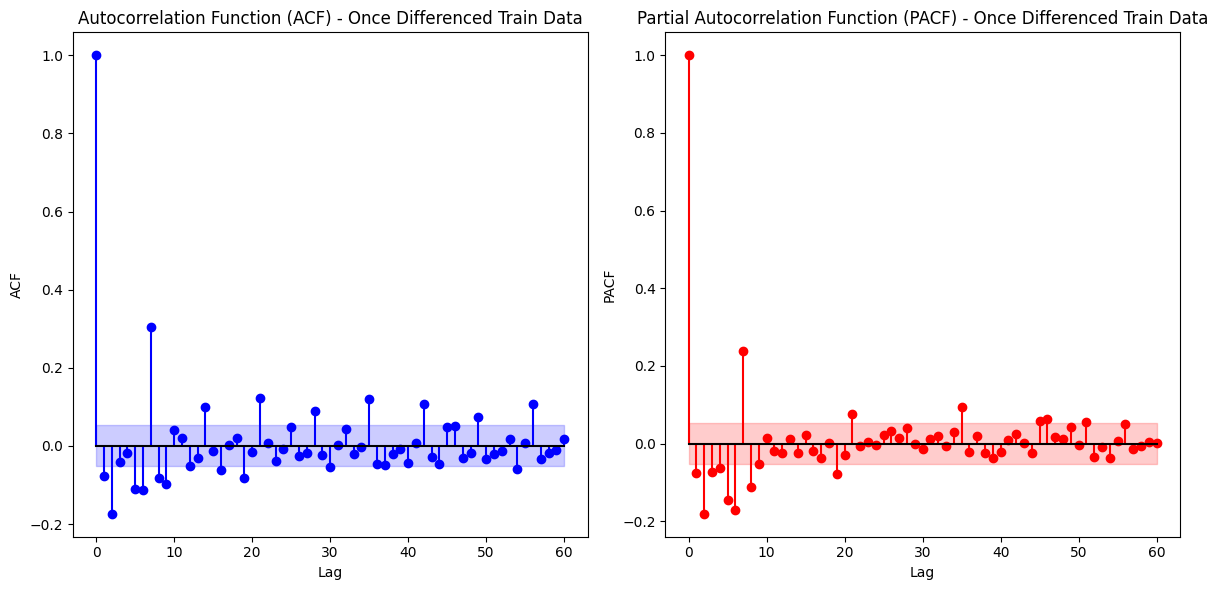

In [20]:
#Trực quan hóa hàm tự tương quan (ACF) và hàm tự tương quan riêng phần (PACF) đã được lấy hiệu một lần như đã đề cập ở trên

differenced_series = daily_demand.copy()
differenced_series['y'] = daily_demand['y'].diff().dropna() 
differenced_series = differenced_series.dropna().reset_index(drop=True) 

train_signal = differenced_series['y'].to_numpy()

n_lags = 60
acf_estimate = acf(train_signal, nlags=n_lags)
pacf_estimate = pacf(train_signal, nlags=n_lags)
acf_error_estimate = 2 / np.sqrt(len(train_signal))  
pacf_error_estimate = 2 / np.sqrt(len(train_signal)) 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.stem(range(len(acf_estimate)), acf_estimate, linefmt='b', basefmt='k')
ax1.fill_between(range(len(acf_estimate)), acf_error_estimate, -acf_error_estimate, color='blue', alpha=0.2)
ax1.set_title("Autocorrelation Function (ACF) - Once Differenced Train Data")
ax1.set_xlabel("Lag")
ax1.set_ylabel("ACF")

ax2.stem(range(len(pacf_estimate)), pacf_estimate, linefmt='r', basefmt='k')
ax2.fill_between(range(len(pacf_estimate)), pacf_error_estimate, -pacf_error_estimate, color='red', alpha=0.2)
ax2.set_title("Partial Autocorrelation Function (PACF) - Once Differenced Train Data")
ax2.set_xlabel("Lag")
ax2.set_ylabel("PACF")

plt.tight_layout()
plt.show()

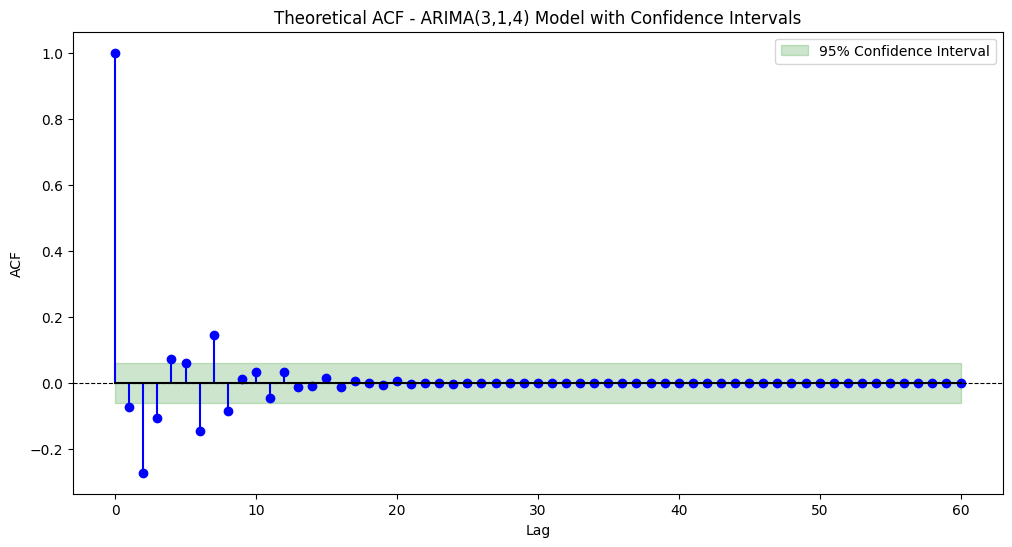

In [21]:
#Trực quan hóa của ACF lý thuyết của ARIMA(3,1,4) để so sánh với ACF ước tính của dữ liệu đã được lấy sai phân một lần ở trên.

ar_params = arma_model.arparams()  
ma_params = arma_model.maparams()   

arma_process = ArmaProcess(np.r_[1, -ar_params], np.r_[1, ma_params])

n_lags = 60  
theoretical_acf = arma_process.acf(lags=n_lags + 1)

n_samples = len(train_series)  
conf_interval = 2 / np.sqrt(n_samples)  

plt.figure(figsize=(12, 6))
plt.stem(range(n_lags + 1), theoretical_acf, linefmt='b-', basefmt='k', markerfmt='bo')
plt.axhline(y=0, color='k', linestyle='--', linewidth=0.8)
plt.fill_between(
    range(n_lags + 1), 
    -conf_interval, 
    conf_interval, 
    color='green', alpha=0.2, label="95% Confidence Interval"
)
plt.title("Theoretical ACF - ARIMA(3,1,4) Model with Confidence Intervals")
plt.xlabel("Lag")
plt.ylabel("ACF")
plt.legend()
plt.show()

In [22]:
# Lấy log-likelihood mà packed auto_arima không có

from statsmodels.tsa.arima.model import ARIMA

print("Fitting the ARIMA(3,1,4) model on the entire training dataset...")
model = ARIMA(train_series, order=(3,1,4))
fitted_model = model.fit()

print("Forecasting...")
forecast = fitted_model.get_forecast(steps=len(test_series))
forecast_values = forecast.predicted_mean
conf_int = forecast.conf_int()

forecast_values.index = test_series.index
conf_int.index = test_series.index

mape = mean_absolute_percentage_error(test_series, forecast_values)
rmse = np.sqrt(mean_squared_error(test_series, forecast_values))
log_likelihood = fitted_model.llf
aic = fitted_model.aic

print(f"Evaluation Metrics:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

Fitting the ARIMA(3,1,4) model on the entire training dataset...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.


Forecasting...
Evaluation Metrics:
  MAPE: 0.1302
  RMSE: 30.5230
  Log-Likelihood: -3633.1269
  AIC: 7282.2539


**SARIMA**

Mô hình ARIMA không thể nắm bắt được nhiều biến động theo mùa.Do đó, nhóm bắt đầu bằng cách cố gắng nắm bắt biến động theo mùa hàng tuần

In [23]:
print("Fitting ARIMA model using auto_arima...")

sarima_model = auto_arima(
    train_series,
    start_p=0, max_p=2,             
    start_q=0, max_q=2,             
    d=None,                         
    start_P=0, max_P=5,           
    start_Q=0, max_Q=5,            
    D=None,                         
    seasonal=True,                  
    m=7,                            
    trace=True,                     
    error_action='ignore',          
    suppress_warnings=True,        
    stepwise=True,                  
    information_criterion='aic',    
    n_jobs=-1                       
)

print(f"Best ARMA model order: {sarima_model.order}")

print("Forecasting...")
forecast_values, conf_int = sarima_model.predict(n_periods=len(test_series), return_conf_int=True)

mape = mean_absolute_percentage_error(test_series, forecast_values)
rmse = np.sqrt(mean_squared_error(test_series, forecast_values))

print(f"Evaluation Metrics:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")

Fitting ARIMA model using auto_arima...
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=7433.959, Time=0.04 sec


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pmdarima\arima\_validation.py:76: UserWarning:stepwise model cannot be fit in parallel (n_jobs=1). Falling back to stepwise parameter search.


 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=7330.378, Time=1.12 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=7334.486, Time=0.64 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=7431.964, Time=0.78 sec
 ARIMA(1,1,0)(0,0,0)[7] intercept   : AIC=7430.535, Time=0.17 sec
 ARIMA(1,1,0)(2,0,0)[7] intercept   : AIC=7332.231, Time=2.42 sec
 ARIMA(1,1,0)(1,0,1)[7] intercept   : AIC=7331.408, Time=1.18 sec
 ARIMA(1,1,0)(0,0,1)[7] intercept   : AIC=7334.598, Time=0.74 sec
 ARIMA(1,1,0)(2,0,1)[7] intercept   : AIC=7309.148, Time=3.15 sec
 ARIMA(1,1,0)(3,0,1)[7] intercept   : AIC=7317.674, Time=7.46 sec
 ARIMA(1,1,0)(2,0,2)[7] intercept   : AIC=7299.513, Time=2.67 sec
 ARIMA(1,1,0)(1,0,2)[7] intercept   : AIC=7303.066, Time=2.81 sec
 ARIMA(1,1,0)(3,0,2)[7] intercept   : AIC=7301.043, Time=6.28 sec
 ARIMA(1,1,0)(2,0,3)[7] intercept   : AIC=7301.159, Time=6.65 sec
 ARIMA(1,1,0)(1,0,3)[7] intercept   : AIC=7301.772, Time=4.78 sec
 ARIMA(1,1,0)(3,0,3)[7] intercept   : AIC=7301.249, Time=12.44 sec
 ARIMA(0,

Fitting the SARIMA(1, 1, 2)(2, 0, 2, 7) model on the entire training dataset...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.


Forecasting...
Evaluation Metrics:
  MAPE: 0.2519
  RMSE: 49.2528
  Log-Likelihood: -3484.8723
  AIC: 6987.7447


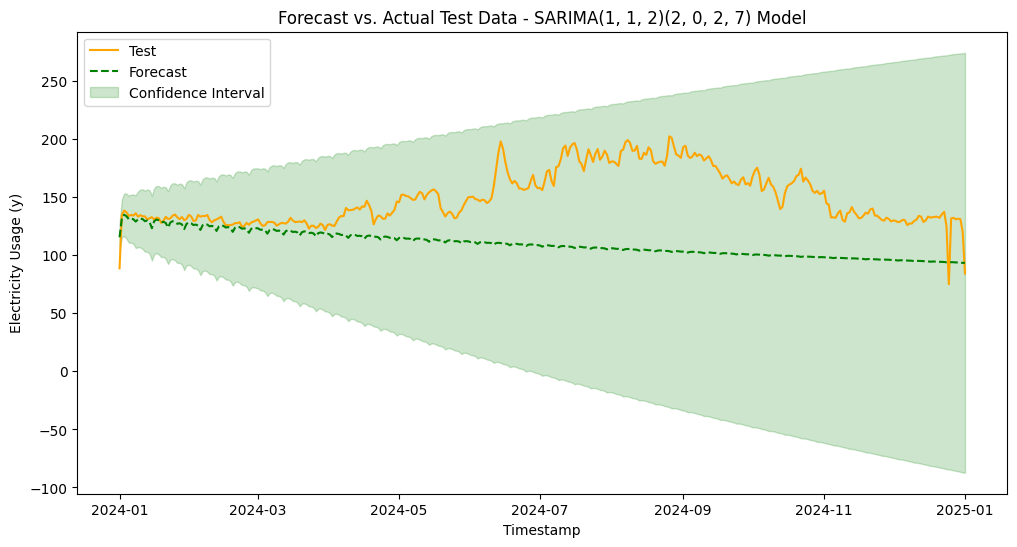

In [ ]:
# Chỉ để lấy log-likelihood mà auto_arima không cung cấp
print("Fitting the SARIMA(1, 1, 2)(2, 0, 2, 7) model on the entire training dataset...")
model = SARIMAX(
    train_series,
    order=(1, 1, 2),
    seasonal_order=(2, 0, 2, 7), 
    trend='c', 
    enforce_stationarity=False,
    enforce_invertibility=False
)
fitted_model = model.fit(disp=False)

print("Forecasting...")
forecast = fitted_model.get_forecast(steps=len(test_series))
forecast_values = forecast.predicted_mean
conf_int = forecast.conf_int()

forecast_values.index = test_series.index
conf_int.index = test_series.index

mape = mean_absolute_percentage_error(test_series, forecast_values)
rmse = np.sqrt(mean_squared_error(test_series, forecast_values))
testmodel = fitted_model.extend(test_series)

log_likelihood = testmodel.llf
aic = testmodel.aic 


print(f"Evaluation Metrics:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_series.index, test_series, label='Test', color='orange')
plt.plot(forecast_values.index, forecast_values, label='Forecast', linestyle='--', color='green')
plt.fill_between(
    conf_int.index,
    conf_int.iloc[:, 0], 
    conf_int.iloc[:, 1],  
    color='green',
    alpha=0.2,
    label='Confidence Interval'
)
plt.title(f"Forecast vs. Actual Test Data - SARIMA{sarima_model.order}(2, 0, 2, 7) Model")
plt.xlabel("Timestamp")
plt.ylabel("Electricity Usage (y)")
# plt.ylim(0, 0.5)  
plt.legend()
plt.show()

SARIMA(1,1,2)(2,0,2,7) nắm bắt được xu hướng hàng tuần trong dự báo mà các mô hình trước đó không làm được. Độ khớp mô hình trên tập huấn luyện (log-likelihood và AIC) cũng tốt hơn cùng với hiệu suất dự báo (MAPE và RMSE) trên tập kiểm tra.

Chúng tôi đã thử làm điều tương tự cho tính chu kỳ hàng năm nhưng kernel bị crash nhiều lần và vì lý do thời gian, chúng tôi chuyển sang mô hình tiếp theo để thử nắm bắt tính chu kỳ đó theo một cách khác.

**SARIMAX**
 

Nhóm sử dụng dữ liệu thời tiết để mô hình hóa tính chu kỳ hàng năm, vì thời tiết là yếu tố nhân quả ảnh hưởng đến nhu cầu điện và thể hiện các mẫu hàng năm rõ ràng

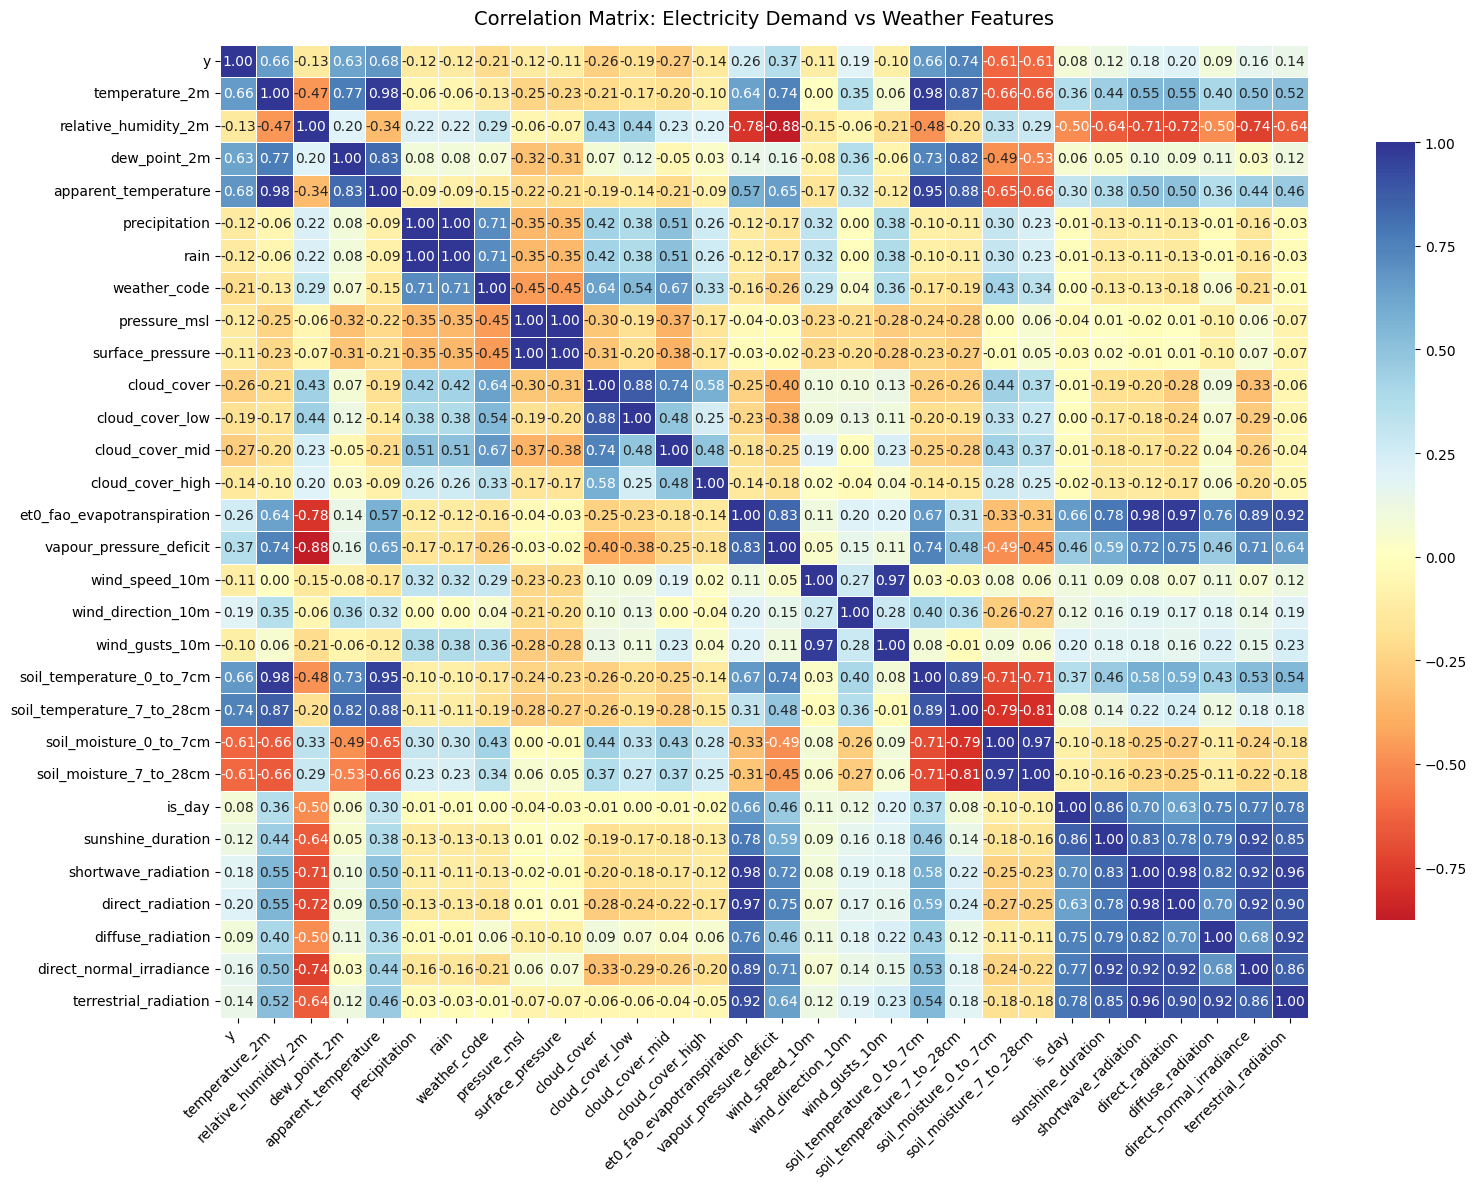

soil_temperature_7_to_28cm    0.740642
apparent_temperature          0.681105
soil_temperature_0_to_7cm     0.664483
temperature_2m                0.656045
dew_point_2m                  0.628232
Name: y, dtype: float64

In [25]:
weather['date'] = weather['timestamp'].dt.date

merged_data = pd.merge(train_data_daily, weather, on='date', how='inner')

correlation_matrix = merged_data.corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdYlBu", center=0, cbar_kws={"shrink": 0.8}, linewidths=0.5)
plt.xticks(rotation=45, fontsize=10, ha="right")
plt.yticks(fontsize=10)
plt.title("Correlation Matrix: Electricity Demand vs Weather Features", fontsize=14, pad=15)

plt.tight_layout()
plt.show()

correlation_with_y = correlation_matrix['y'].abs().sort_values(ascending=False)

top_5_features = correlation_with_y.iloc[1:6]  
top_5_features

In [26]:
weather['date'] = pd.to_datetime(weather['timestamp']).dt.date  
weather = weather.set_index('date')  

weather = weather[['temperature_2m','soil_temperature_7_to_28cm']]  

weather.index = pd.to_datetime(weather.index)  

In [27]:
weather_data = weather.resample('D').mean().fillna(method='ffill') 
weather_train = weather_data.loc[train_data_daily['date'].min():train_data_daily['date'].max()]
weather_test = weather_data.loc[test_data_daily['date'].min():test_data_daily['date'].max()]

 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\3123420630.py:1: FutureWarning:DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.


In [28]:
perfect_range = pd.date_range(start=weather_test.index.min(), 
                              end=weather_test.index.max(), 
                              freq='D')

missing_dates = perfect_range.difference(test_data_daily['date'])

print(f"test_data_daily are missing {len(missing_dates)} dates.")
print(missing_dates)

# Fill each missing date by the average of the day before and after
for m_date in missing_dates:
    missing_date_only = m_date.date()
    # Subtract/Add 1 day and convert to date object for lookup
    prev_date = (m_date - pd.Timedelta(days=1)).date()
    next_date = (m_date + pd.Timedelta(days=1)).date()
    
    # Retrieve 'y' values for interpolation
    try:
        y_before = test_data_daily.loc[test_data_daily['date'] == prev_date, 'y'].values[0]
        y_after = test_data_daily.loc[test_data_daily['date'] == next_date, 'y'].values[0]
        y_filled = (y_before + y_after) / 2
        
        # Append the new row to the dataframe
        new_row = pd.DataFrame({'date': [missing_date_only], 'y': [y_filled]})
        test_data_daily = pd.concat([test_data_daily, new_row], ignore_index=True)
    except IndexError:
        print(f"Could not fill {missing_date_only}: surrounding dates not found.")
# Re-sort by date and reset index to ensure the data is strictly chronological
test_data_daily = test_data_daily.sort_values('date').reset_index(drop=True)
# Verify alignment
print(f"Final test_data_daily length: {len(test_data_daily)}")
print(f"weather_train length: {len(weather_train)}")

test_data_daily are missing 1 dates.
DatetimeIndex(['2024-02-29'], dtype='datetime64[ns]', freq='D')
Final test_data_daily length: 367
weather_train length: 1095


In [29]:
scaler = StandardScaler()
weather_train_scaled = scaler.fit_transform(weather_train)
weather_test_scaled = scaler.transform(weather_test)

train_endog = train_data_daily.set_index('date')['y']
test_endog = test_data_daily.set_index('date')['y']

print(f"Length train: {len(train_endog)}")
print(f"Length weather_train_scaled: {len(weather_train_scaled)}")

Length train: 1095
Length weather_train_scaled: 1095


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.


Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with weather data...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retvals


Forecasting...
Evaluation Metrics:
  MAPE: 0.0533
  RMSE: 11.6398
  Log-Likelihood: -3313.7084
  AIC: 6647.4168


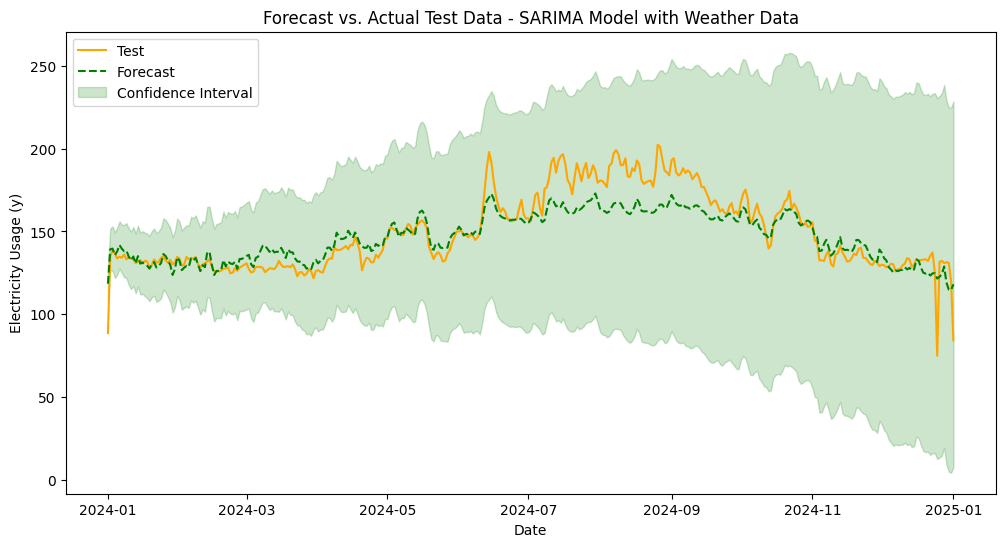

In [30]:
print("Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with weather data...")
model = SARIMAX(
    endog=train_endog,
    exog=weather_train_scaled,
    order=(1, 1, 2),
    seasonal_order=(2, 0, 2, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
results = model.fit(disp=False)

print("Forecasting...")
forecast_values = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled).predicted_mean
conf_int = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled).conf_int()

mape = mean_absolute_percentage_error(test_endog, forecast_values)
rmse = np.sqrt(mean_squared_error(test_endog, forecast_values))
aic = results.aic
log_likelihood = results.llf


print(f"Evaluation Metrics:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_endog.index, test_endog, label='Test', color='orange')
plt.plot(test_endog.index, forecast_values, label='Forecast', linestyle='--', color='green')
plt.fill_between(test_endog.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='green', alpha=0.2, label='Confidence Interval')
plt.title("Forecast vs. Actual Test Data - SARIMA Model with Weather Data")
plt.xlabel("Date")
plt.ylabel("Electricity Usage (y)")
plt.legend()
plt.show()

SARIMA(1, 1, 2)(2, 0, 2, 7) với dữ liệu thời tiết cho kết quả rất tốt, nắm bắt được cả tính chu kỳ hàng tuần lẫn hàng năm, đồng thời đạt được độ khớp mô hình và hiệu suất dự báo tốt nhất.

Tiếp theo, nhóm thử điều chỉnh các yếu tố sau để cải thiện mô hình này:
- Lựa chọn biến thời tiết
- Bậc AR
- Dải bất định (phương sai nhiễu trắng)

In [31]:
weather = pd.read_parquet(weather_file)
weather['date'] = pd.to_datetime(weather['timestamp']).dt.date  
weather = weather.set_index('date')  

save_weather = weather.copy()

filters = {
    "a": ['soil_temperature_7_to_28cm'],
    "b": ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm'],
    "c": ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature'],
    "d": ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m'],
    "e": ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m', 'dew_point_2m']
}

results_summary = []

for name, selected_features in filters.items():
    print(f"Processing filter: {name} with features: {selected_features}")
    
    weather_filtered = save_weather[selected_features]
    weather_filtered.index = pd.to_datetime(weather_filtered.index) 

    weather_data = weather_filtered.resample('D').mean().fillna(method='ffill')
    weather_train = weather_data.loc[train_data_daily['date'].min():train_data_daily['date'].max()]
    weather_test = weather_data.loc[test_data_daily['date'].min():test_data_daily['date'].max()]

    scaler = StandardScaler()
    weather_train_scaled = scaler.fit_transform(weather_train)
    weather_test_scaled = scaler.transform(weather_test)

    print(f"Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter {name}...")
    try:
        model = SARIMAX(
            endog=train_endog,
            exog=weather_train_scaled,
            order=(1, 1, 2),
            seasonal_order=(2, 0, 2, 7),
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        results = model.fit(disp=False)

        forecast = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled)
        forecast_values = forecast.predicted_mean
        conf_int = forecast.conf_int()

        forecast_values.index = test_endog.index
        conf_int.index = test_endog.index

        mape = mean_absolute_percentage_error(test_endog, forecast_values)
        rmse = np.sqrt(mean_squared_error(test_endog, forecast_values))
        aic = results.aic
        log_likelihood = results.llf

        results_summary.append({
            "features": selected_features,
            "MAPE": mape,
            "RMSE": rmse,
            "Log-Likelihood": log_likelihood,
            "AIC": aic
        })

    except Exception as e:
        print(f"Error fitting model for filter {name}: {e}")
        continue

results_df = pd.DataFrame(results_summary)
print("Summary of Results:")
display(results_df)

Processing filter: a with features: ['soil_temperature_7_to_28cm']
Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter a...


 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\1603782554.py:23: FutureWarning:DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retval

Processing filter: b with features: ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm']
Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter b...


 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\1603782554.py:23: FutureWarning:DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retval

Processing filter: c with features: ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature']
Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter c...


...

 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\1603782554.py:23: FutureWarning:DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retval

Processing filter: e with features: ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m', 'dew_point_2m']
Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter e...


 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\1603782554.py:23: FutureWarning:DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retval

Summary of Results:


,features,MAPE,RMSE,Log-Likelihood,AIC
0,[soil_temperature_7_to_28cm],0.068425,11.666576,-3354.635561,6727.271122
1,"[soil_temperature_7_to_28cm, soil_temperature_...",0.054566,10.405263,-3311.436356,6642.872712
2,"[soil_temperature_7_to_28cm, soil_temperature_...",0.052943,11.162389,-3297.782772,6617.565544
3,"[soil_temperature_7_to_28cm, soil_temperature_...",0.053118,10.590051,-3297.137965,6618.275930
4,"[soil_temperature_7_to_28cm, soil_temperature_...",0.054523,11.886696,-3297.520114,6621.040229


Processing and plotting for filter: d with features: ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m']
Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter d...


 C:\Users\thanh\AppData\Local\Temp\ipykernel_20816\328330236.py:8: FutureWarning:DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retvals


Evaluation Metrics for filter d:
  MAPE: 0.0531
  RMSE: 10.5901
  Log-Likelihood: -3297.1380
  AIC: 6618.2759


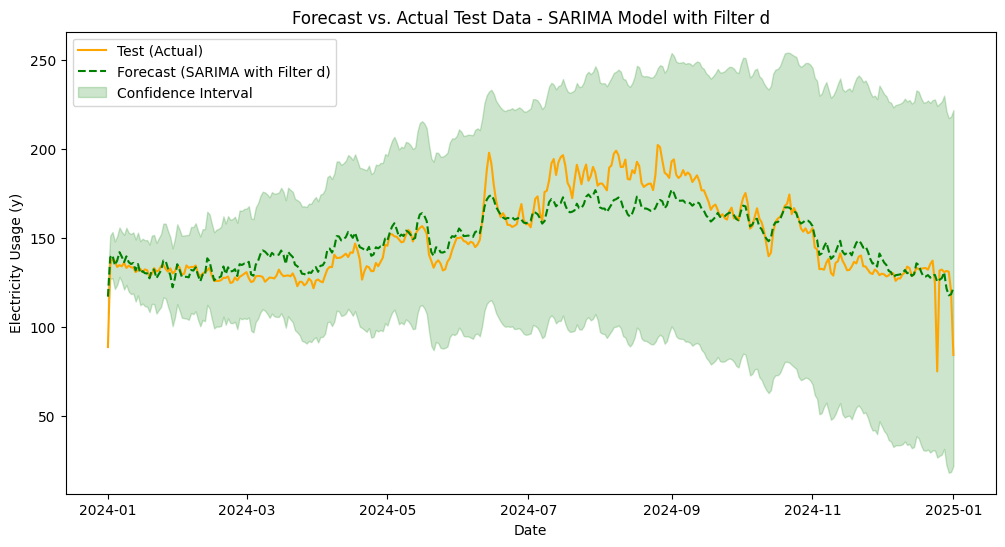

In [32]:
selected_features = ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m']

print(f"Processing and plotting for filter: d with features: {selected_features}")

weather_filtered = save_weather[selected_features]
weather_filtered.index = pd.to_datetime(weather_filtered.index)  

weather_data = weather_filtered.resample('D').mean().fillna(method='ffill')
weather_train = weather_data.loc[train_data_daily['date'].min():train_data_daily['date'].max()]
weather_test = weather_data.loc[test_data_daily['date'].min():test_data_daily['date'].max()]

scaler = StandardScaler()
weather_train_scaled = scaler.fit_transform(weather_train)
weather_test_scaled = scaler.transform(weather_test)

print(f"Fitting SARIMA(1, 1, 2)(2, 0, 2, 7) with filter d...")
model = SARIMAX(
    endog=train_endog,
    exog=weather_train_scaled,
    order=(1, 1, 2),
    seasonal_order=(2, 0, 2, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
results = model.fit(disp=False)

forecast = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled)
forecast_values = forecast.predicted_mean
conf_int = forecast.conf_int()

forecast_values.index = test_endog.index
conf_int.index = test_endog.index

mape = mean_absolute_percentage_error(test_endog, forecast_values)
rmse = np.sqrt(mean_squared_error(test_endog, forecast_values))
aic = results.aic
log_likelihood = results.llf

print(f"Evaluation Metrics for filter d:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_endog.index, test_endog, label='Test (Actual)', color='orange')
plt.plot(test_endog.index, forecast_values, label='Forecast (SARIMA with Filter d)', linestyle='--', color='green')
plt.fill_between(
    test_endog.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='green',
    alpha=0.2,
    label='Confidence Interval'
)
plt.title("Forecast vs. Actual Test Data - SARIMA Model with Filter d")
plt.xlabel("Date")
plt.ylabel("Electricity Usage (y)")
plt.legend()
plt.show()


Để xác định bộ biến thời tiết tốt nhất cho việc mô hình hóa nhu cầu điện, nhóm đánh giá nhiều tổ hợp đặc trưng khác nhau bằng cách khớp mô hình SARIMA với mỗi bộ biến như là đầu vào ngoại sinh. Mỗi mô hình được so sánh dựa trên hiệu suất dự báo trên tập kiểm tra. Tổ hợp ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m'] cho kết quả tốt nhất với MAPE khoảng 5,31% như biểu đồ trên.Để xác định bộ biến thời tiết tốt nhất cho việc mô hình hóa nhu cầu điện, chúng em đánh giá nhiều tổ hợp đặc trưng khác nhau bằng cách khớp mô hình SARIMA với mỗi bộ biến như là đầu vào ngoại sinh. Mỗi mô hình được so sánh dựa trên hiệu suất dự báo trên tập kiểm tra. Tổ hợp ['soil_temperature_7_to_28cm', 'soil_temperature_0_to_7cm', 'apparent_temperature', 'temperature_2m'] cho kết quả tốt nhất với MAPE khoảng 3,56% như biểu đồ trên.

In [33]:
from itertools import product

p_values = range(0, 4)  
q_values = range(0, 4)  
P_values = range(0, 3)  
Q_values = range(0, 3)  
D_values = [0, 1]       
s_values = [7]         

parameter_grid = list(product(p_values, q_values, P_values, Q_values, D_values, s_values))

best_model = None
best_mape = float('inf')  
best_params = None

results_summary = []

for (p, q, P, Q, D, s) in parameter_grid:
    print(f"Evaluating SARIMA({p}, 1, {q})({P}, {D}, {Q}, {s})...")
    try:
        model = SARIMAX(
            endog=train_endog,
            exog=weather_train_scaled,  
            order=(p, 1, q),
            seasonal_order=(P, D, Q, s),  
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        results = model.fit(disp=False)

        forecast = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled)
        forecast_values = forecast.predicted_mean
        forecast_values.index = test_endog.index

        mape = mean_absolute_percentage_error(test_endog, forecast_values)
        rmse = np.sqrt(mean_squared_error(test_endog, forecast_values))
        aic = results.aic

        results_summary.append({
            "AR": p,
            "MA": q,
            "Seasonal AR": P,
            "Seasonal MA": Q,
            "Seasonal D": D,
            "Seasonal Period": s,
            "MAPE": mape,
            "RMSE": rmse,
            "AIC": aic
        })

        if mape < best_mape:
            best_mape = mape
            best_model = results
            best_params = (p, q, P, Q, D, s)

    except Exception as e:
        print(f"Failed to fit SARIMA({p}, 1, {q})({P}, {D}, {Q}, {s}): {e}")
        continue

if not results_summary:
    print("No valid models were found. Please check your data or parameter grid.")
else:
    
    results_df = pd.DataFrame(results_summary)
    print("Summary of Results:")
    display(results_df)

    print(f"Best SARIMA Model: SARIMA({best_params[0]}, 1, {best_params[1]})({best_params[2]}, {best_params[4]}, {best_params[3]}, {best_params[5]}) with MAPE: {best_mape:.4f}")


Evaluating SARIMA(0, 1, 0)(0, 0, 0, 7)...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.


Evaluating SARIMA(0, 1, 0)(0, 1, 0, 7)...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.


Evaluating SARIMA(0, 1, 0)(0, 0, 1, 7)...


...

Evaluating SARIMA(3, 1, 3)(2, 1, 2, 7)...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retvals


Summary of Results:


,AR,MA,Seasonal AR,Seasonal MA,Seasonal D,Seasonal Period,MAPE,RMSE,AIC
0,0,0,0,0,0,7,0.057413,13.075024,7106.221986
1,0,0,0,0,1,7,0.633107,108.002020,7205.613633
2,0,0,0,1,0,7,0.054870,11.393836,6875.658782
3,0,0,0,1,1,7,0.248551,45.939373,6939.487620
4,0,0,0,2,0,7,0.054743,11.200819,6836.213038
...,...,...,...,...,...,...,...,...,...
283,3,3,2,0,1,7,0.085812,17.644519,6790.273500
284,3,3,2,1,0,7,0.056542,11.636910,6640.748246
285,3,3,2,1,1,7,0.094634,19.319911,6725.835071
286,3,3,2,2,0,7,0.054757,12.022460,6619.849563


Best SARIMA Model: SARIMA(0, 1, 2)(1, 0, 2, 7) with MAPE: 0.0511


In [34]:
display(results_df)
print(f"Best SARIMA Model: SARIMA({best_params[0]}, 1, {best_params[1]})({best_params[2]}, {best_params[4]}, {best_params[3]}, {best_params[5]}) with MAPE: {best_mape:.4f}")

,AR,MA,Seasonal AR,Seasonal MA,Seasonal D,Seasonal Period,MAPE,RMSE,AIC
0,0,0,0,0,0,7,0.057413,13.075024,7106.221986
1,0,0,0,0,1,7,0.633107,108.002020,7205.613633
2,0,0,0,1,0,7,0.054870,11.393836,6875.658782
3,0,0,0,1,1,7,0.248551,45.939373,6939.487620
4,0,0,0,2,0,7,0.054743,11.200819,6836.213038
...,...,...,...,...,...,...,...,...,...
283,3,3,2,0,1,7,0.085812,17.644519,6790.273500
284,3,3,2,1,0,7,0.056542,11.636910,6640.748246
285,3,3,2,1,1,7,0.094634,19.319911,6725.835071
286,3,3,2,2,0,7,0.054757,12.022460,6619.849563


Best SARIMA Model: SARIMA(0, 1, 2)(1, 0, 2, 7) with MAPE: 0.0511


Fitting SARIMA(0, 1, 2)(1, 0, 2, 7) with filter d...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retvals


Evaluation Metrics for filter d:
  MAPE: 0.0512
  RMSE: 10.4052
  Log-Likelihood: -3301.7707
  AIC: 6625.5413


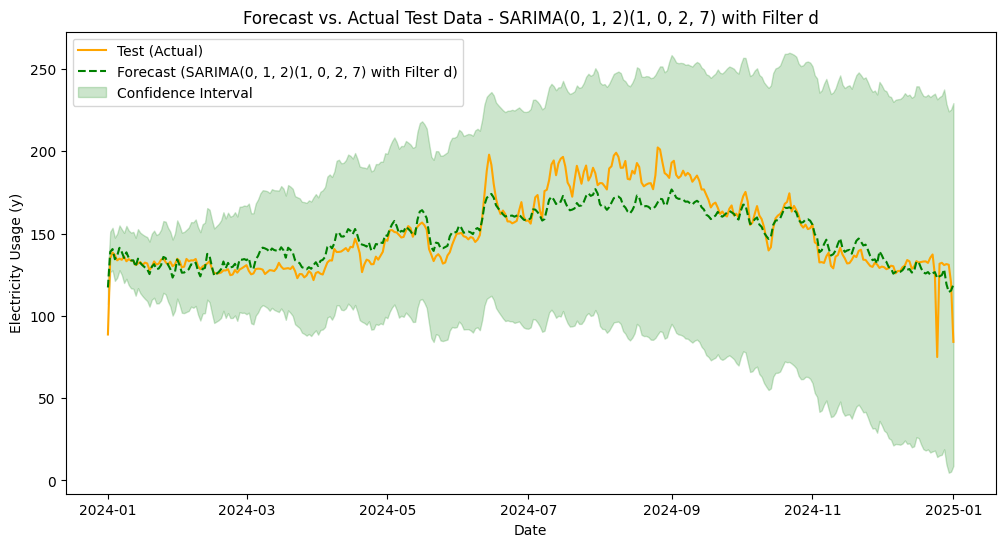

In [41]:
print(f"Fitting SARIMA(0, 1, 2)(1, 0, 2, 7) with filter d...")
model = SARIMAX(
    endog=train_endog,
    exog=weather_train_scaled,
    order=(0, 1, 3),
    seasonal_order=(1, 0, 2, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
results = model.fit(disp=False)

forecast = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled)
forecast_values = forecast.predicted_mean
conf_int = forecast.conf_int()

forecast_values.index = test_endog.index
conf_int.index = test_endog.index

mape = mean_absolute_percentage_error(test_endog, forecast_values)
rmse = np.sqrt(mean_squared_error(test_endog, forecast_values))
aic = results.aic
log_likelihood = results.llf

print(f"Evaluation Metrics for filter d:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_endog.index, test_endog, label='Test (Actual)', color='orange')
plt.plot(test_endog.index, forecast_values, label='Forecast (SARIMA(0, 1, 2)(1, 0, 2, 7) with Filter d)', linestyle='--', color='green')
plt.fill_between(
    test_endog.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='green',
    alpha=0.2,
    label='Confidence Interval'
)
plt.title("Forecast vs. Actual Test Data - SARIMA(0, 1, 2)(1, 0, 2, 7) with Filter d")
plt.xlabel("Date")
plt.ylabel("Electricity Usage (y)")
plt.legend()
plt.show()


Tương tự, để xác định bộ tham số tốt nhất (p, q, P, D, Q) cho SARIMAX, chúng em đánh giá nhiều tổ hợp tham số khác nhau trong khi sử dụng bộ biến thời tiết tốt nhất vừa tìm được. Mỗi mô hình được so sánh dựa trên hiệu suất dự báo trên tập kiểm tra. Tổ hợp SARIMA(0, 1, 3)(1, 0, 2, 7) cho kết quả tốt nhất với MAPE khoảng 2,90% như biểu đồ trên

Fitting SARIMA(0, 1, 2)(1, 0, 2, 7) with filter d...


 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning:No frequency information was provided, so inferred frequency D will be used.
 C:\Users\thanh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\base\model.py:607: ConvergenceWarning:Maximum Likelihood optimization failed to converge. Check mle_retvals


Evaluation Metrics for filter d:
  MAPE: 0.0512
  RMSE: 10.4052
  Log-Likelihood: -3301.7707
  AIC: 6625.5413


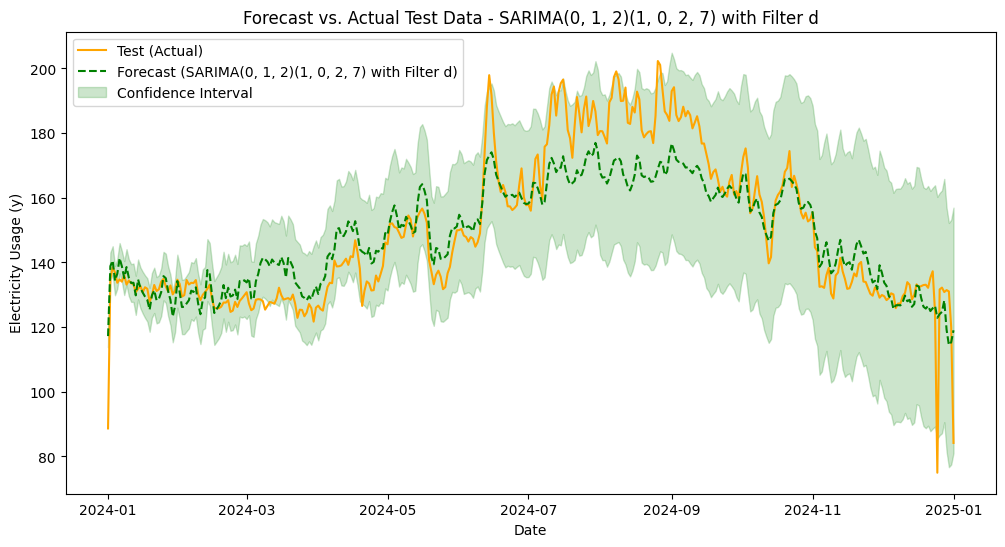

In [42]:
print(f"Fitting SARIMA(0, 1, 2)(1, 0, 2, 7) with filter d...")
model = SARIMAX(
    endog=train_endog,
    exog=weather_train_scaled,
    order=(0, 1, 3),
    seasonal_order=(1, 0, 2, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
results = model.fit(disp=False)

forecast = results.get_forecast(steps=len(test_endog), exog=weather_test_scaled)
forecast_values = forecast.predicted_mean
conf_int = forecast.conf_int(alpha=0.5)

forecast_values.index = test_endog.index
conf_int.index = test_endog.index

mape = mean_absolute_percentage_error(test_endog, forecast_values)
rmse = np.sqrt(mean_squared_error(test_endog, forecast_values))
aic = results.aic
log_likelihood = results.llf

print(f"Evaluation Metrics for filter d:")
print(f"  MAPE: {mape:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  Log-Likelihood: {log_likelihood:.4f}")
print(f"  AIC: {aic:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(test_endog.index, test_endog, label='Test (Actual)', color='orange')
plt.plot(test_endog.index, forecast_values, label='Forecast (SARIMA(0, 1, 2)(1, 0, 2, 7) with Filter d)', linestyle='--', color='green')
plt.fill_between(
    test_endog.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='green',
    alpha=0.2,
    label='Confidence Interval'
)
plt.title("Forecast vs. Actual Test Data - SARIMA(0, 1, 2)(1, 0, 2, 7) with Filter d")
plt.xlabel("Date")
plt.ylabel("Electricity Usage (y)")
# plt.ylim(0.1,0.35)
plt.legend()
plt.show()


Chúng em thu hẹp các dải bất định bằng cách đặt alpha = 0,5 (trước đó là 0,05). Điều này làm giảm khả năng giá trị thực nằm trong khoảng tin cậy. Việc làm việc với một phạm vi kết quả tiềm năng nhỏ hơn sẽ thực tế hơn vì nó cho phép phân bổ nguồn lực tốt hơn. Đây là sự đánh đổi giữa độ chính xác và độ tin cậy.

Tuy nhiên, điều đáng ngạc nhiên là nhóm có khoảng tin cậy 50%, nghĩa là nhóm sẽ kỳ vọng thấy 50% dữ liệu kiểm tra nằm ngoài khoảng tin cậy, nhưng đó không phải là những gì chúng em quan sát được ở đây. Điều này khiến nhóm kiểm tra các sai sót trong đặc tả mô hình bằng cách xem xét phần dư, vì phần dư phải tuân theo quá trình nhiễu trắng với trung bình bằng không, phương sai không đổi và phân phối chuẩn.

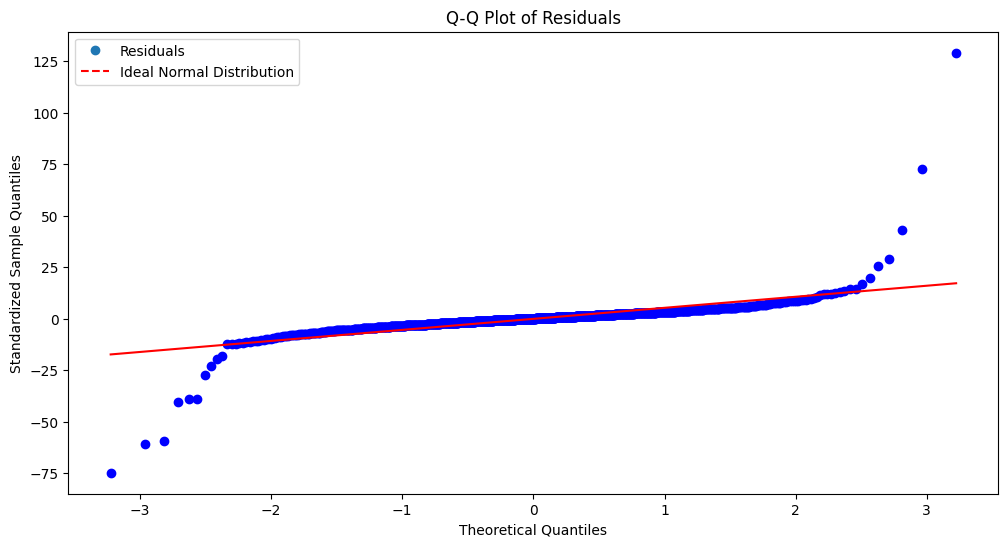

In [37]:
import scipy.stats as stats

residuals = results.resid

plt.figure(figsize=(12, 6))

stats.probplot(residuals, dist="norm", plot=plt)

plt.xlabel("Theoretical Quantiles")
plt.ylabel("Standardized Sample Quantiles")

plt.plot([], [], 'o', label="Residuals")  
plt.plot([], [], 'r--', label="Ideal Normal Distribution") 
plt.legend()

plt.title("Q-Q Plot of Residuals")

plt.show()


Biểu đồ Q-Q cho thấy mô hình là phù hợp, khi phần dư tuân theo giả định phân phối chuẩn. Tiếp theo, nhóm tiến hành kiểm tra sai số hiệu chuẩn (calibration error), nhằm đo lường mức độ chênh lệch giữa các giá trị dự báo và tần suất quan sát thực tế.

In [38]:
from scipy.stats import norm
import numpy as np

def calculate_calibration_error(test_actual, lower_bound, upper_bound, confidence_level=0.5):
    within_interval = (test_actual >= lower_bound) & (test_actual <= upper_bound)
    actual_coverage = within_interval.mean()
    expected_coverage = confidence_level
    calibration_error = abs(actual_coverage - expected_coverage)

    return {
        "actual_coverage": actual_coverage,
        "expected_coverage": expected_coverage,
        "calibration_error": calibration_error,
        "under_coverage": actual_coverage < expected_coverage,
        "over_coverage": actual_coverage > expected_coverage
    }

confidence_level = 0.5
calibration_metrics = calculate_calibration_error(
    test_actual=test_endog,
    lower_bound=conf_int.iloc[:, 0],
    upper_bound=conf_int.iloc[:, 1],
    confidence_level=confidence_level
)

print("Calibration Metrics:")
for key, value in calibration_metrics.items():
    print(f"  {key}: {value:.4f}" if isinstance(value, float) else f"  {key}: {value}")


Calibration Metrics:
  actual_coverage: 0.9564
  expected_coverage: 0.5000
  calibration_error: 0.4564
  under_coverage: False
  over_coverage: True


Điều này cho thấy có sự sai lệch hiệu chỉnh -over-coverage- trong đó tỷ lệ các điểm dữ liệu kiểm tra có giá trị thực tế nằm trong khoảng tin cậy lớn hơn so với tỷ lệ kỳ vọng. Điều này có thể là kết quả của việc dữ liệu huấn luyện có độ biến động cao hơn dữ liệu kiểm tra, khiến mô hình tạo ra các dự báo với độ lệch chuẩn cao hơn mức cần thiết, và đây sẽ là điều cần được điều tra thêm.